# ADIB anode-free substrate screening: full workflow

**Question.** Which conductive materials can serve as substrates (anodic current collectors)
for stable, reversible Al deposition in chloroaluminate Al dual-ion batteries?
Al itself is always the plated species (4 Al₂Cl₇⁻ + 3 e⁻ → Al + 7 AlCl₄⁻); only the
substrate is screened.

**Framing.** Physics-informed screening with ML assistance, not black-box ML prediction of
battery performance. Status: *computational screening framework and preliminary candidate
identification*.

**Knowledge types, kept apart everywhere:**
**A computed** (Materials Project or derived from MP energies) ·
**B literature** (verified sources with DOI) · **C inferred** (ML predictions, tiers).

Thresholds and validation rules were fixed before any result was seen: `docs/descriptors.md`.

## 0. Settings

* `DEMO = True`: the Phase-1 ML cells use **synthetic** data (a unit test of the ML code; runs
  without an API key). All screening cells below use the **real, cached** Materials Project data
  in `data/` and need no key or network.
* `REFIT_REAL_ML = False`: the real Phase-1 benchmark (1,566 entries, 76 LOGO + 23 element
  folds, permutation importance) takes ~1.5 h on a laptop; its saved outputs in `results/` are
  loaded instead. Set `True` (with `MP_API_KEY`) to recompute.

In [1]:
import os, sys, io, contextlib, warnings, subprocess
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

DEMO = True
REFIT_REAL_ML = False

## 1. Phase-1 ML infrastructure: formation energy, leakage-controlled

Formation energy is a *benchmark* target with full MP coverage; it is not the screening
criterion. For materials already in MP, the DFT value is used directly.

In [2]:
import substrate_screening as ss
if DEMO:
    print(ss.DEMO_FEATURESET_WARNING)
    df = ss.make_synthetic()
    with contextlib.redirect_stdout(io.StringIO()):
        df, labels = ss.add_magpie(df)
        sets = ss.feature_sets(df, labels, False)
    feats = list(dict.fromkeys(c for cols in sets.values() for c in cols))
    audit = ss.audit_leakage(df, feats + list(ss.LEAKY_EXCLUDED), df["group"])
    print("SYNTHETIC leakage audit - the planted E_hull leak must be caught:")
    display(audit[audit["flags"].str.contains("LEAK") | (audit["role"] == "excluded")])
    print(f"{df['group'].nunique()} synthetic groups -> "
          f"{len(ss.grouped_folds(df, df['target'], df['group']))} LOGO folds")

DEMO: the feature-set comparison carries no information until real data is run -
  the synthetic target depends mainly on the DFT-style features, so composition-only
  loses by construction.


SYNTHETIC leakage audit - the planted E_hull leak must be caught:


,column,role,exact,spearman,solo_R2,grp_const,flags
131,energy_above_hull,excluded,0.212222,0.438821,0.05239,0.0,LEAK:identity


76 synthetic groups -> 76 LOGO folds


In [3]:
if REFIT_REAL_ML:
    subprocess.run([sys.executable, "substrate_screening.py", "--key", os.environ["MP_API_KEY"],
                    "--out", "results/model_comparison.csv", "--audit-out", "results/leakage_audit.csv",
                    "--oof-out", "results/oof_predictions.csv", "--data-out", "results/mp_ml_dataset.csv"],
                   check=True)
audit = pd.read_csv("results/leakage_audit.csv")
print("REAL-DATA leakage audit (1,566 MP entries, 76 chemical systems):")
print(audit["flags"].str.split(",").explode().value_counts().to_string())
display(audit[audit["flags"].str.contains("LEAK|review") | (audit["role"] == "excluded")])

REAL-DATA leakage audit (1,566 MP entries, 76 chemical systems):
flags
ok               67
group-proxy      64
LEAK:identity     1


,column,role,exact,spearman,solo_R2,grp_const,flags
131,energy_above_hull,excluded,0.088761,0.187438,-0.034265,0.013158,LEAK:identity


In [4]:
mc_path = "results/model_comparison.csv"
if os.path.exists(mc_path):
    mc = pd.read_csv(mc_path)
    for fs in mc["feature_set"].unique():
        print(f"\n{fs} features - pooled / system-balanced R2 (+/- group-bootstrap SE)")
        display(pd.concat([ss.results_table(mc[mc.feature_set == fs].reset_index(drop=True), w)
                           .set_index("model").add_suffix(f" [{w}]")
                           for w in ss.WEIGHTINGS], axis=1).filter(like="R2"))
    for fs in mc["feature_set"].unique():
        ss.interpret(mc[mc.feature_set == fs].reset_index(drop=True), fs)
else:
    print("results/model_comparison.csv not found - run with REFIT_REAL_ML = True")


full features - pooled / system-balanced R2 (+/- group-bootstrap SE)


,random_R2 [pooled],grouped_R2 [pooled],element_R2 [pooled],random_R2 [balanced],grouped_R2 [balanced],element_R2 [balanced]
model,,,,,,
Ridge,0.948 +/- 0.014,0.888 +/- 0.023,0.801 +/- 0.032,0.912 +/- 0.028,0.860 +/- 0.039,0.769 +/- 0.044
RandomForest,0.972 +/- 0.008,0.930 +/- 0.019,0.634 +/- 0.088,0.951 +/- 0.015,0.921 +/- 0.021,0.742 +/- 0.038
XGBoost,0.973 +/- 0.008,0.924 +/- 0.014,0.612 +/- 0.072,0.949 +/- 0.016,0.920 +/- 0.021,0.737 +/- 0.031



composition-only features - pooled / system-balanced R2 (+/- group-bootstrap SE)


,random_R2 [pooled],grouped_R2 [pooled],element_R2 [pooled],random_R2 [balanced],grouped_R2 [balanced],element_R2 [balanced]
model,,,,,,
Ridge,0.940 +/- 0.017,0.870 +/- 0.027,0.747 +/- 0.035,0.893 +/- 0.034,0.825 +/- 0.047,0.706 +/- 0.048
RandomForest,0.966 +/- 0.010,0.931 +/- 0.021,0.634 +/- 0.095,0.943 +/- 0.017,0.920 +/- 0.021,0.741 +/- 0.040
XGBoost,0.966 +/- 0.010,0.922 +/- 0.014,0.634 +/- 0.076,0.941 +/- 0.018,0.920 +/- 0.020,0.748 +/- 0.035



[full]
  Best on grouped CV, pooled:   RandomForest (R2 0.930 +/- 0.019, MAE 0.234 +/- 0.023)
  Best on grouped CV, balanced: RandomForest (R2 0.921 +/- 0.021, MAE 0.199 +/- 0.012)
  Random-to-grouped R2 gap, pooled: 0.042 +/- 0.015
    -> The gap is modest but real (> 2 SE).
  Random-to-grouped R2 gap, balanced: 0.029 +/- 0.010
    -> The gap is modest but real (> 2 SE).
  Pooled minus balanced grouped R2 (RandomForest): 0.009 +/- 0.018
    -> Pooled and balanced agree within 2 SE; the large systems are not distorting the headline.
  Leave-one-element-out R2 (RandomForest): pooled 0.634 +/- 0.088, balanced 0.742 +/- 0.038
    -> The drop from grouped to element (pooled) is large (> 2 SE).
  RandomForest beats Ridge by only 0.042 +/- 0.021 pooled grouped R2 (Ridge 0.888 +/- 0.023).
  Prefer Ridge - the interpretability is worth more than the marginal accuracy,
  and it is a defensible choice to justify in a viva.

[composition-only]
  Best on grouped CV, pooled:   RandomForest (R2 0.9

## 2. ML assistance: an unseen family and the applicability domain

Transition-metal aluminides are **not** in the Phase-1 training set, so their DFT formation
energies test the composition-only model on genuinely unseen chemistry.

In [5]:
dom = pd.read_csv("results/ml_domain_summary.csv")
display(dom.round(3))
d = pd.read_csv("results/ml_domain.csv"); a = d[d.family == "aluminide"]
from scipy.stats import spearmanr
for col in ("knn_dist", "rf_std", "model_spread"):
    print(f"Spearman({col}, |RF error|) on aluminides = {spearmanr(a[col], a['abs_err_RandomForest'])[0]:.2f}")

,subset,n_entries,n_compositions,MAE_Ridge,MAE_RandomForest,MAE_XGBoost,mean_knn_dist
0,"aluminides (unseen family), all",128,91,0.276,0.158,0.193,6.344
1,"aluminides, in domain",104,75,0.256,0.166,0.202,5.614
2,"aluminides, out of domain",24,16,0.365,0.121,0.153,9.508
3,other families (systems seen in training),651,229,0.233,0.118,0.107,8.076


Spearman(knn_dist, |RF error|) on aluminides = -0.13
Spearman(rf_std, |RF error|) on aluminides = 0.02
Spearman(model_spread, |RF error|) on aluminides = 0.18


## 3. Candidate space, retrieval, filters

Six families, each with a stated reason (`adib_data.SCREENING_FAMILIES`).
F1: E_hull ≤ 90th-percentile metastability of known crystals (67 meV/atom; 195 for nitrides;
Sun et al. 2016). F2: metallic at the PBE level.

In [6]:
import adib_data as ad, adib_screening as asc
for fam, f in ad.SCREENING_FAMILIES.items():
    print(f"{fam:<10} {len(f['systems']):>2}  {f['rationale']}")
summary = ad.fetch_summary()          # cached: data/screening_summary.csv
print(f"\n{len(summary)} MP entries, {summary.chemsys.nunique()} systems, {summary.formula.nunique()} compositions")

element    19  Conventional current-collector metals and every single-element reference material in the literature table (C = graphite, the nearest MP proxy for graphite paper / glassy carbon).
nitride     9  Metallic transition-metal nitrides; TiN and Cr2N current collectors were measured stable to 2.5-3 V vs Al in AlCl3:[EMIM]Cl (Wang et al., Adv. Sci. 2018).
carbide     9  Metallic refractory carbides, chemically analogous to the nitrides. Hypothesis: no chloroaluminate test found.
boride      9  Metallic transition-metal borides (e.g. TiB2, ZrB2), conductive and chemically inert. Hypothesis: no chloroaluminate test found.
silicide    9  Metallic transition-metal silicides (e.g. MoSi2, WSi2, TiSi2). Hypothesis: no chloroaluminate test found.
aluminide  12  Pre-aluminised substrates: an Al-rich aluminide in equilibrium with Al cannot alloy further during plating. Hypothesis, motivated by Al-V intermetallics forming during Al underpotential deposition on V (Cvetkovic et al., Metals 20


830 MP entries, 67 systems, 330 compositions


## 4. Electrolyte stability windows

Grand-potential phase diagrams open to Al and Cl, with μ_Al = μ°_Al − 3eφ and
μ_Cl = [g(AlCl₃) − μ_Al]/3. **φ_ox** = anodic limit (chlorination or Al extraction),
**φ_red** = Al-alloying limit, **r0** = reaction driving force with Al at 0 V. φ_ox is a
thermodynamic lower bound. Windows are loaded from `results/stability_windows.csv`; delete it to
recompute (~20 min). One example is recomputed live:

In [7]:
import adib_windows as aw
live = aw.scan(ad.load_entries("Al-Cl-W"), ["W"])["W"]
print({k: live[k] for k in ("phi_ox", "ox_mechanism", "ox_products", "phi_red", "kind0", "products0")})
windows = asc.compute_windows(summary)
cands = asc.screen(summary, windows)
display(asc.funnel(summary, cands))

{'phi_ox': 1.03, 'ox_mechanism': np.str_('chlorination'), 'ox_products': 'WCl2', 'phi_red': 0.07, 'kind0': np.str_('alloying'), 'products0': 'Al5W'}


,stage,count
0,MP entries in screening space,830
1,unique compositions,330
2,pass F1 (E_hull window),254
3,pass F1 + F2 (metallic),250
4,phi_ox >= 0.5 V,93
5,phi_ox >= 1.0 V,25
6,phi_ox >= 1.0 V and stable vs Al at 0 V,0
7,high-priority tier (Pareto layers 1-2),22


In [8]:
sens = asc.sensitivity(cands)
display(sens.pivot(index="anodic_cutoff_V", columns="ehull_window_scale", values="n_candidates"))

ehull_window_scale,0.5,1.0,1.5
anodic_cutoff_V,,,
0.0,211,249,270
0.5,84,93,102
1.0,20,25,29
1.5,3,3,3
2.0,1,1,1


## 5. Known-material validation (rules fixed beforehand)

Literature table: `data/literature_benchmark.csv`, every row with electrode side, conditions,
DOI and verification status. Unverified rows are never scored.

In [9]:
lit = pd.read_csv("data/literature_benchmark.csv")
print(lit["verification"].value_counts().to_string())
subprocess.run([sys.executable, "adib_validate.py"], check=True)
v = pd.read_csv("results/validation.csv")
display(v[["substrate", "electrode_side", "potential_type", "exp_potential_V_vs_Al", "phi_ox", "verdict"]])

verification
verbatim-full-text    11
verbatim-abstract      5
none                   5
search-summary         2


,substrate,electrode_side,potential_type,exp_potential_V_vs_Al,phi_ox,verdict
0,Cr,positive current collector test,onset,0.62,0.50,framework agrees
1,stainless steel,positive current collector test,onset,0.92,NaN,insufficient evidence
2,Al,positive current collector test,onset,1.00,0.00,framework agrees - kinetically stable beyond the thermod...
3,Ti,positive current collector test,onset,1.10,0.10,framework agrees - kinetically stable beyond the thermod...
4,Au,positive current collector test,corrodes_at,2.00,1.73,framework agrees
5,Pt,positive current collector test,corrodes_at,2.00,1.55,framework agrees
6,TiN,positive current collector test,stable_up_to,2.50,0.83,framework agrees - kinetically stable beyond the thermod...
7,Cr2N,positive current collector test,stable_up_to,2.50,0.36,framework agrees - kinetically stable beyond the thermod...
8,W,positive current collector test,qualitative,NaN,1.03,insufficient evidence
9,Mo,positive current collector test,qualitative,NaN,0.65,insufficient evidence


## 6. Shortlist: high-priority candidates for future validation

Pareto tiers (no weights), shown for the lowest registered anodic scenario φ_ox ≥ 0.5 V.
Confidence records whether the tier survives the alternative MP energy route.

In [10]:
subprocess.run([sys.executable, "adib_shortlist.py"], check=True)
sl = pd.read_csv("results/shortlist.csv")
display(sl[["priority", "material", "family", "stability (A)", "anodic limit phi_ox (A)",
            "Al interaction at plating (A)", "confidence (C)"]])

,priority,material,family,stability (A),anodic limit phi_ox (A),Al interaction at plating (A),confidence (C)
0,high priority candidate for future validation,C,element,E_hull 3 meV/atom; ICSD-known,2.06 V (chlorination: CCl4); alt. route 1.82 V,reacts with Al at 0 V -> Al4C3 (-0.56 eV/atom),higher: tier robust to energy route; ICSD-known
1,high priority candidate for future validation,Au,element,E_hull 0 meV/atom; ICSD-known,1.73 V (chlorination: AuCl); alt. route 1.58 V,reacts with Al at 0 V -> Al2Au (-1.49 eV/atom),higher: tier robust to energy route; ICSD-known
2,high priority candidate for future validation,Ag,element,E_hull 0 meV/atom; ICSD-known,1.13 V (chlorination: AgCl); alt. route 1.17 V,reacts with Al at 0 V -> AlAg3 (-0.10 eV/atom),higher: tier robust to energy route; ICSD-known
3,high priority candidate for future validation,NbB2,boride,E_hull 0 meV/atom; ICSD-known,0.93 V (chlorination: BCl3 + Nb3Cl8); alt. route 0.82 V,reacts with Al at 0 V -> Al23B50 + NbAl3 (-0.02 eV/atom),lower: tier changes with energy route
4,high priority candidate for future validation,TiB2,boride,E_hull 0 meV/atom; ICSD-known,0.90 V (chlorination: BCl3 + TiCl4); alt. route 0.77 V,does not react with Al at 0 V,lower: tier changes with energy route
5,high priority candidate for future validation,VB2,boride,E_hull 0 meV/atom; ICSD-known,0.90 V (chlorination: Al2VCl8 + BCl3); alt. route 0.85 V,does not react with Al at 0 V,higher: tier robust to energy route; ICSD-known
6,high priority candidate for future validation,V2B3,boride,E_hull 0 meV/atom; ICSD-known,0.59 V (chlorination: Al2VCl8 + VB2); alt. route 0.85 V,does not react with Al at 0 V,higher: tier robust to energy route; ICSD-known
7,high priority candidate for future validation,Pt,element,E_hull 0 meV/atom; ICSD-known,1.55 V (chlorination: PtCl2); alt. route 1.45 V,reacts with Al at 0 V -> Al21Pt8 (-3.00 eV/atom),higher: tier robust to energy route; ICSD-known
8,high priority candidate for future validation,W2N3,nitride,E_hull 0 meV/atom; hypothetical in MP,1.30 V (chlorination: N2 + WNCl3); alt. route 1.22 V,reacts with Al at 0 V -> Al5W + AlN (-1.91 eV/atom),medium: tier robust to energy route; hypothetical in MP
9,high priority candidate for future validation,Nb5N6,nitride,E_hull 0 meV/atom; ICSD-known,1.14 V (chlorination: N2 + NbCl5); alt. route 0.87 V,reacts with Al at 0 V -> AlN + NbAl3 (-1.55 eV/atom),lower: tier changes with energy route


## 7. Figures

01_chemical_space.png


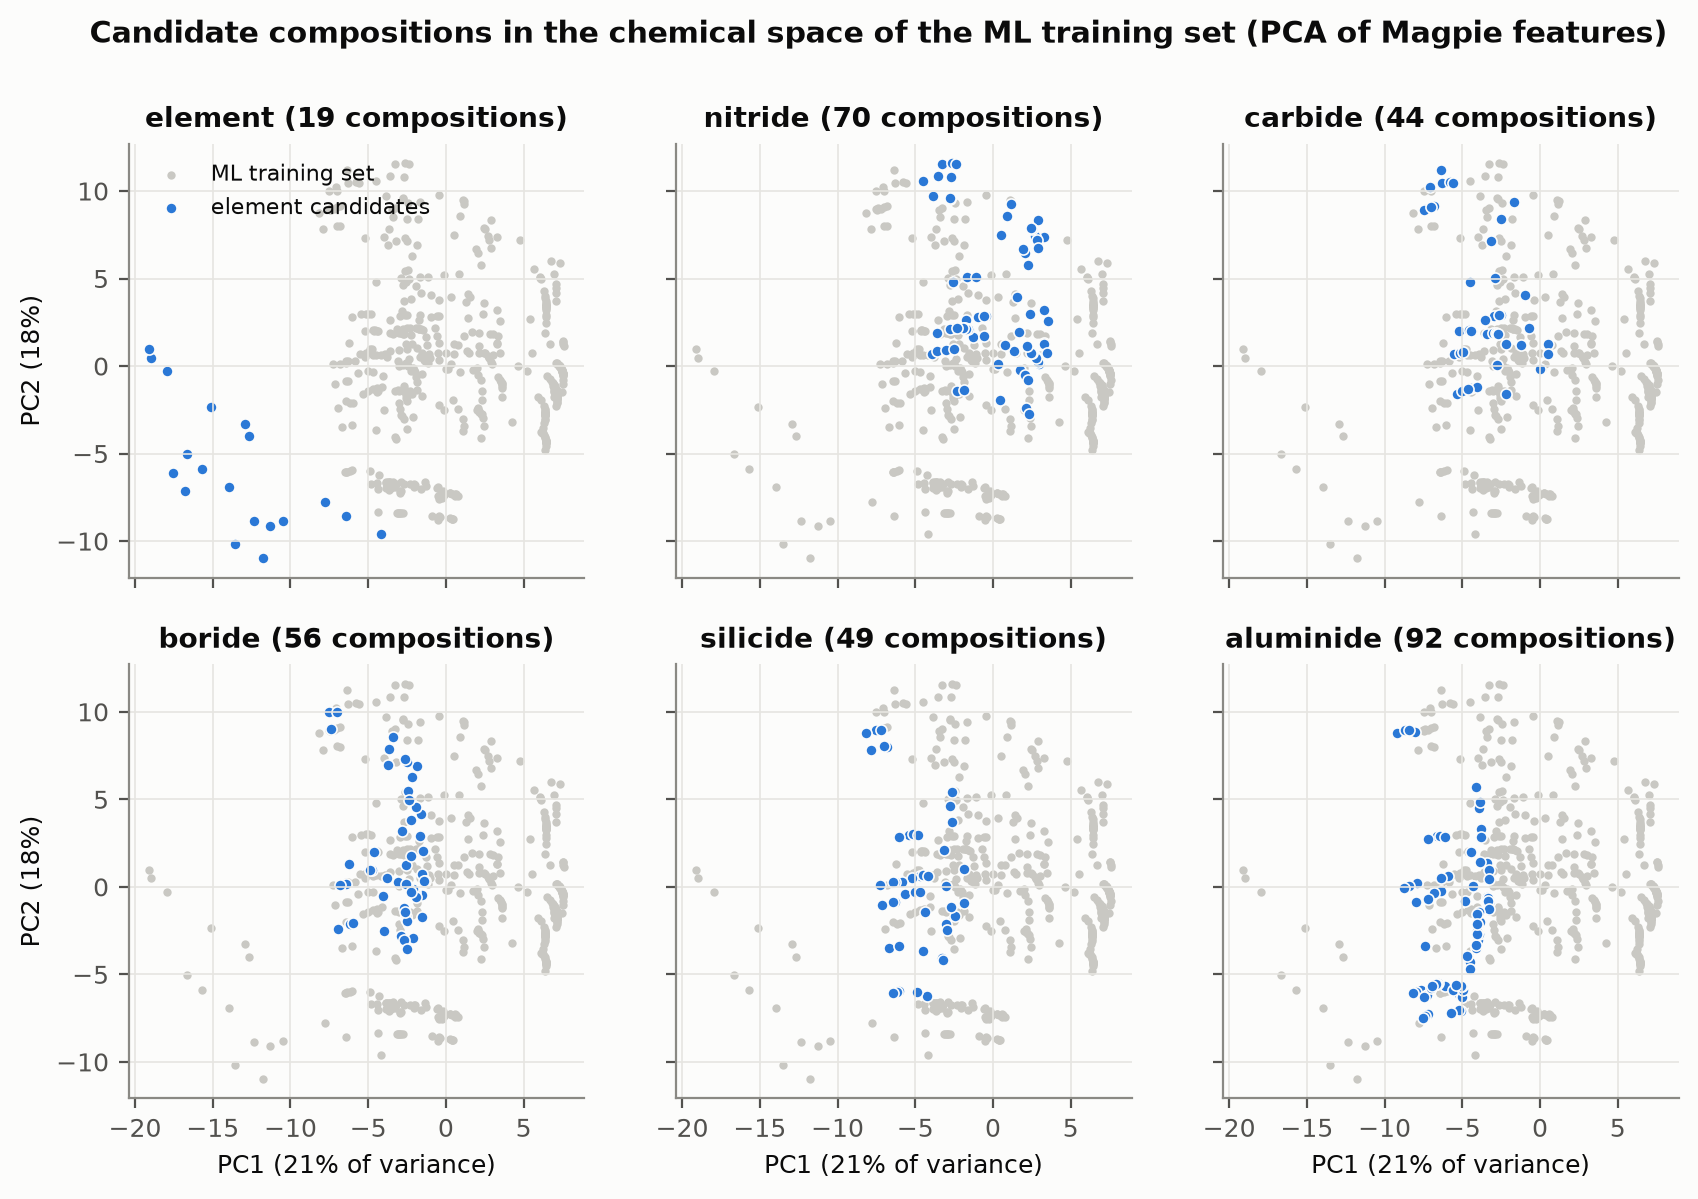

02_stability_distributions.png


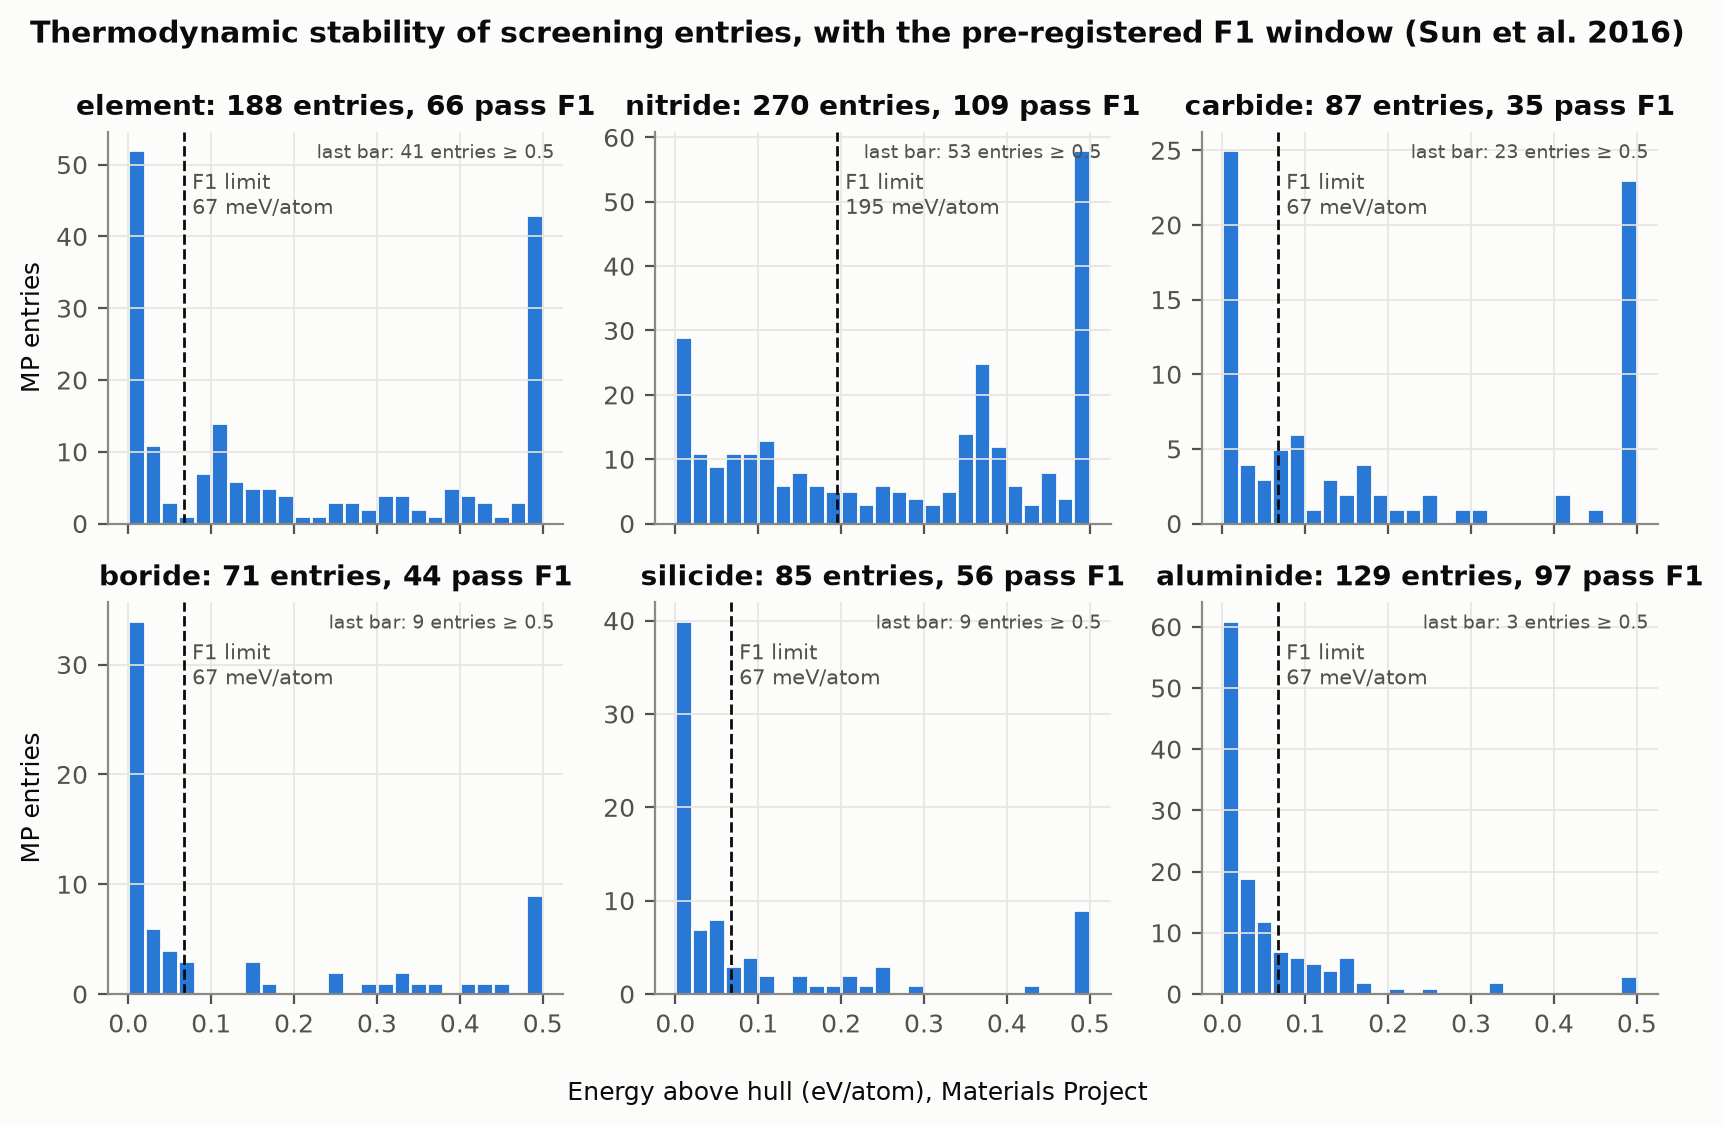

03_formation_energy.png


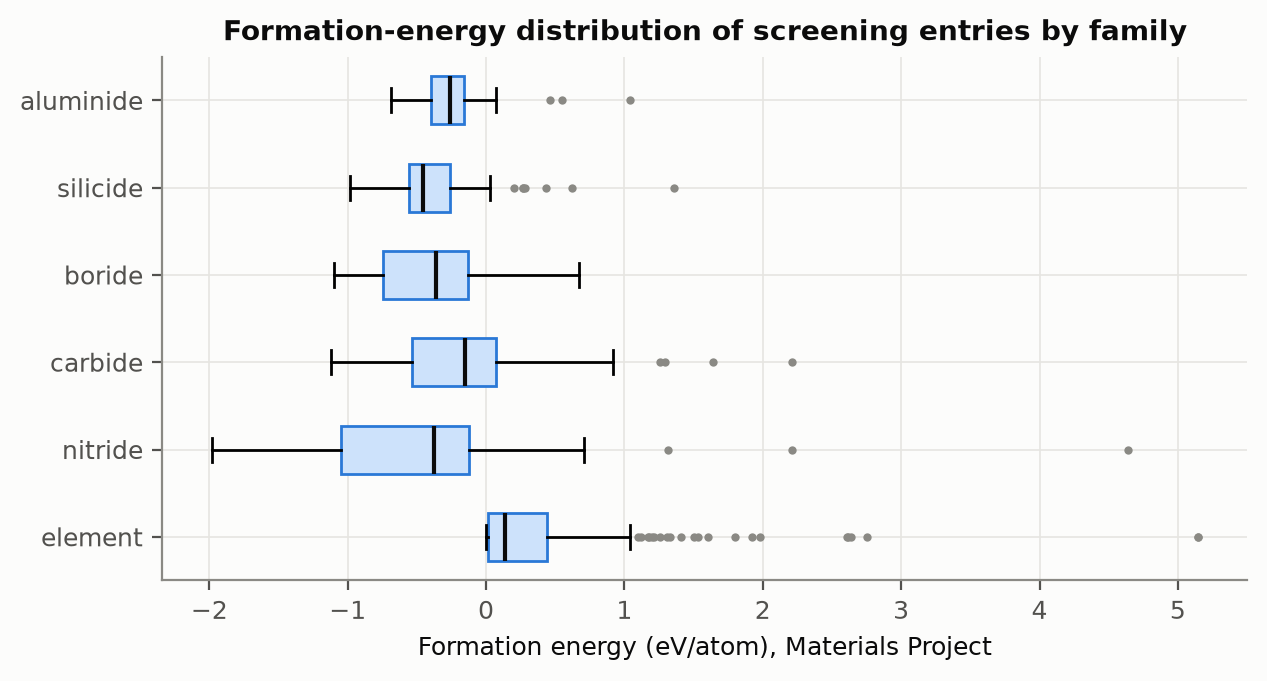

04_model_performance.png


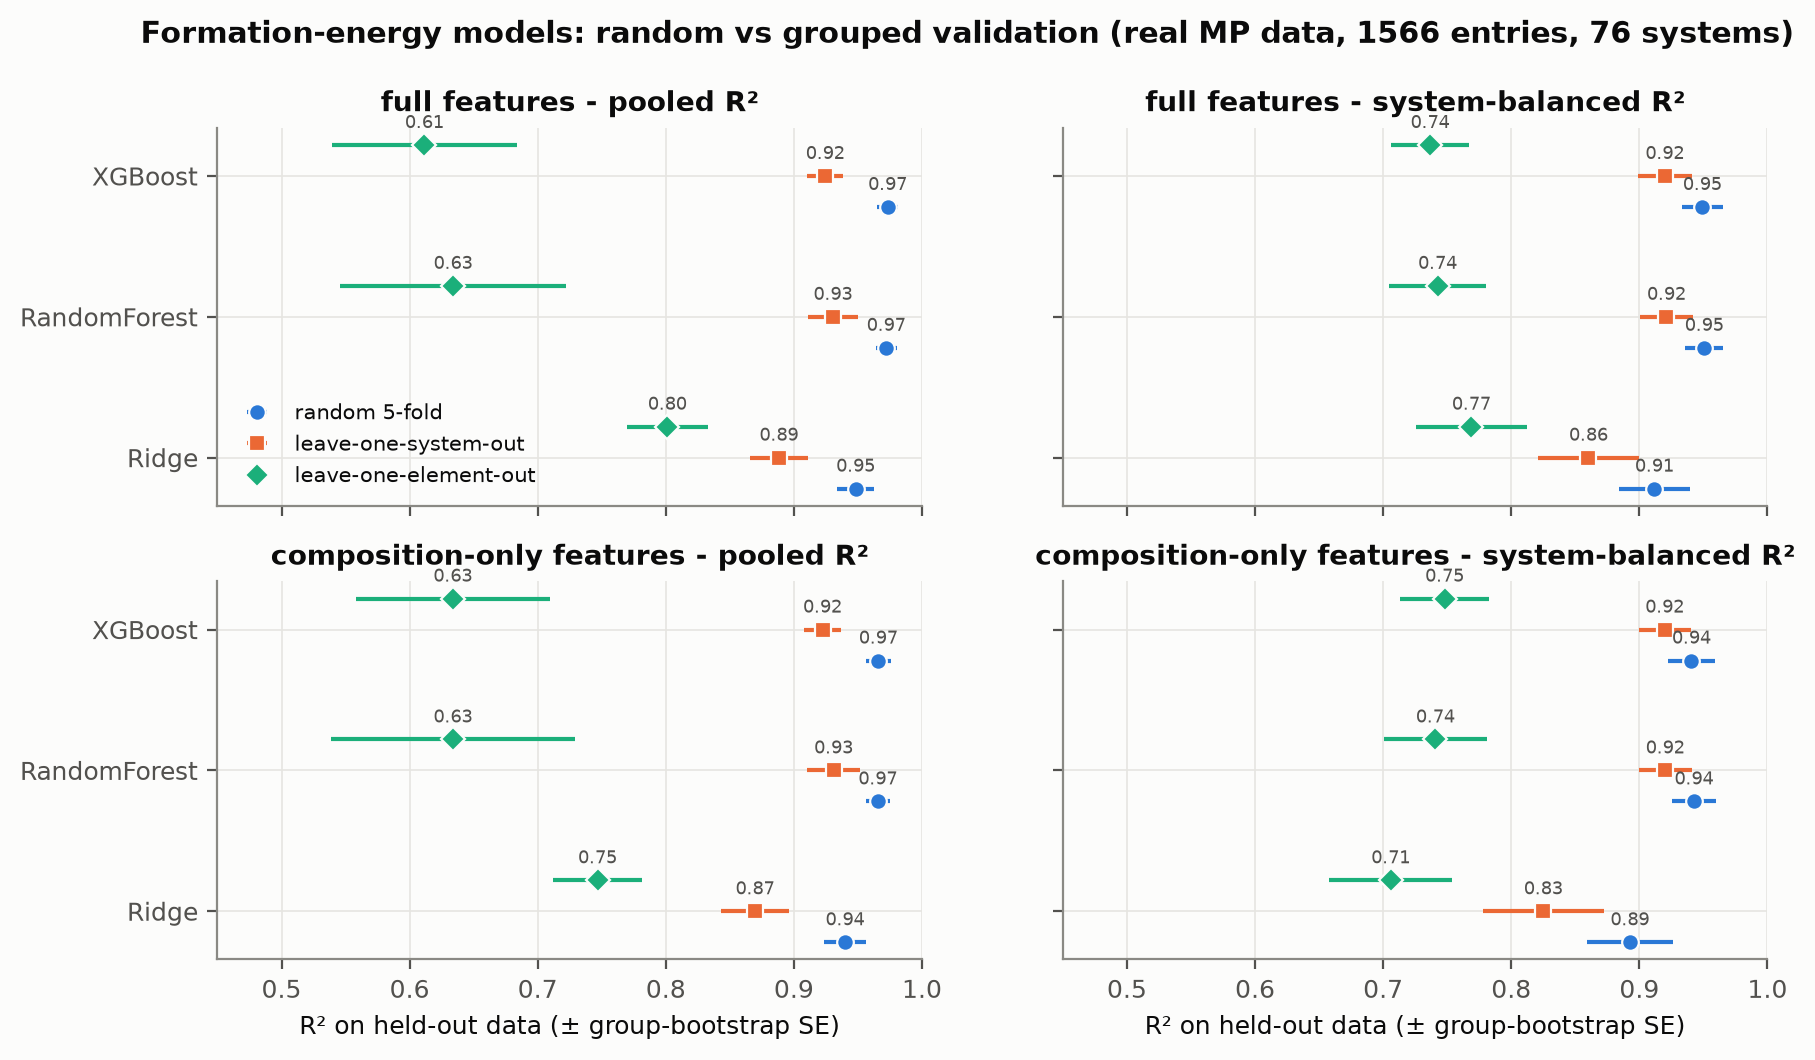

05_random_vs_grouped_gap.png


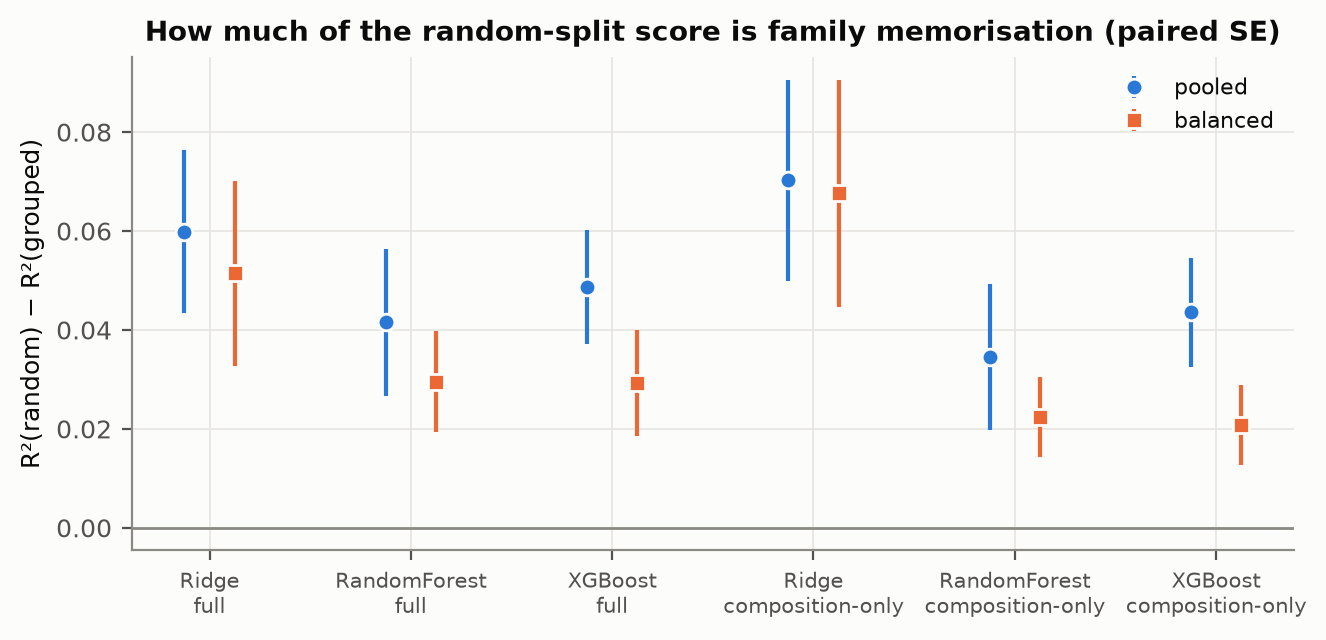

06_feature_importance.png


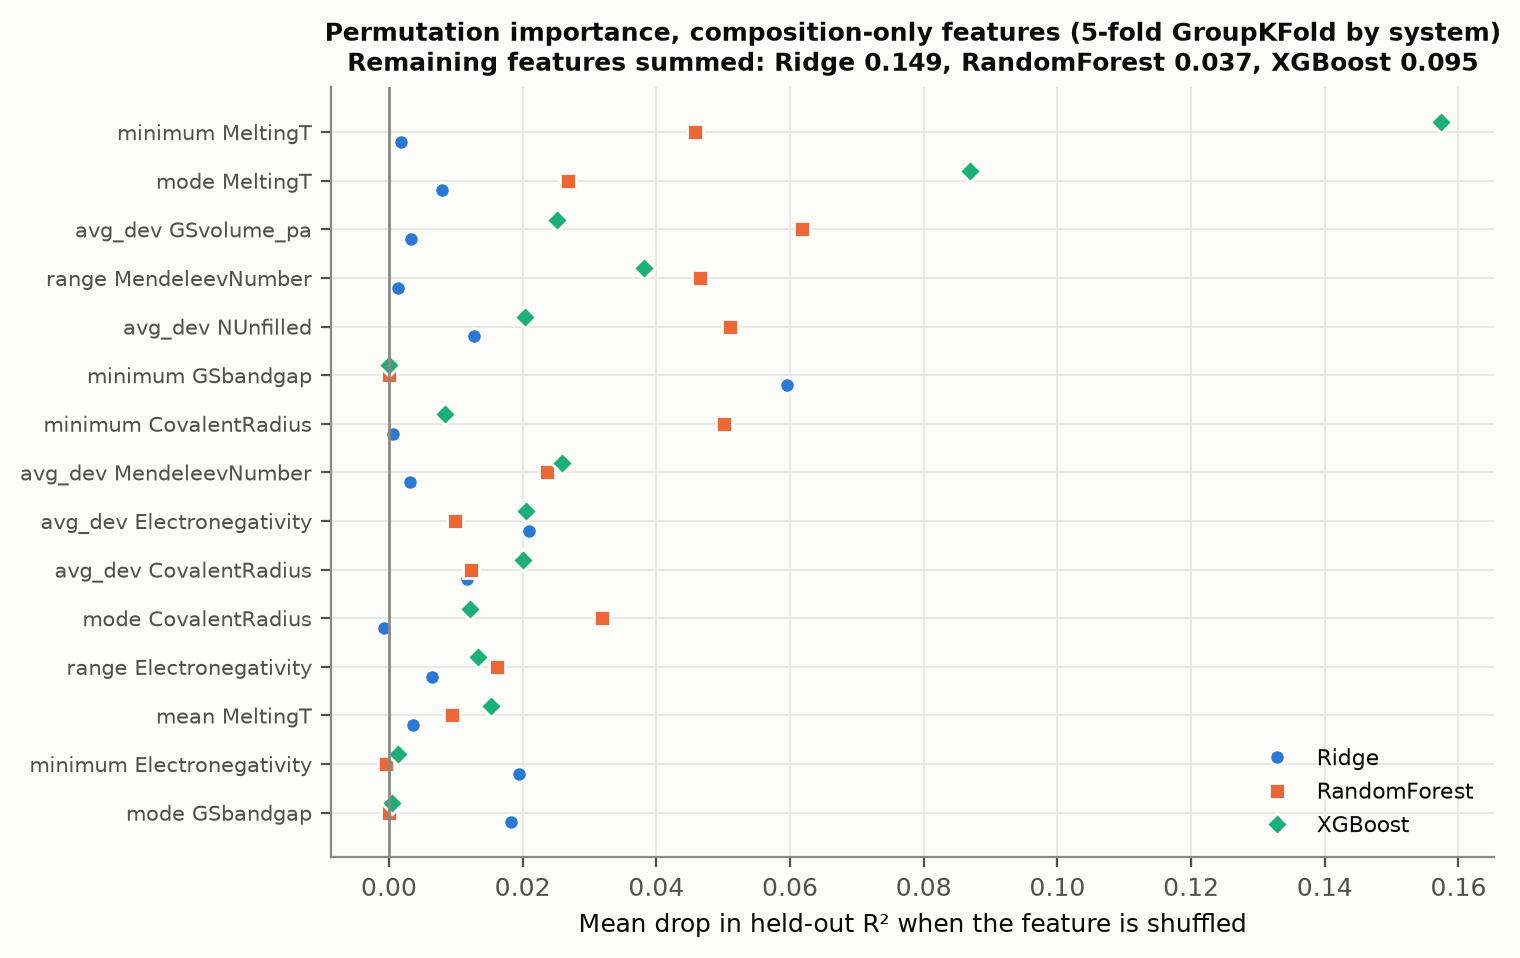

07_screening_funnel.png


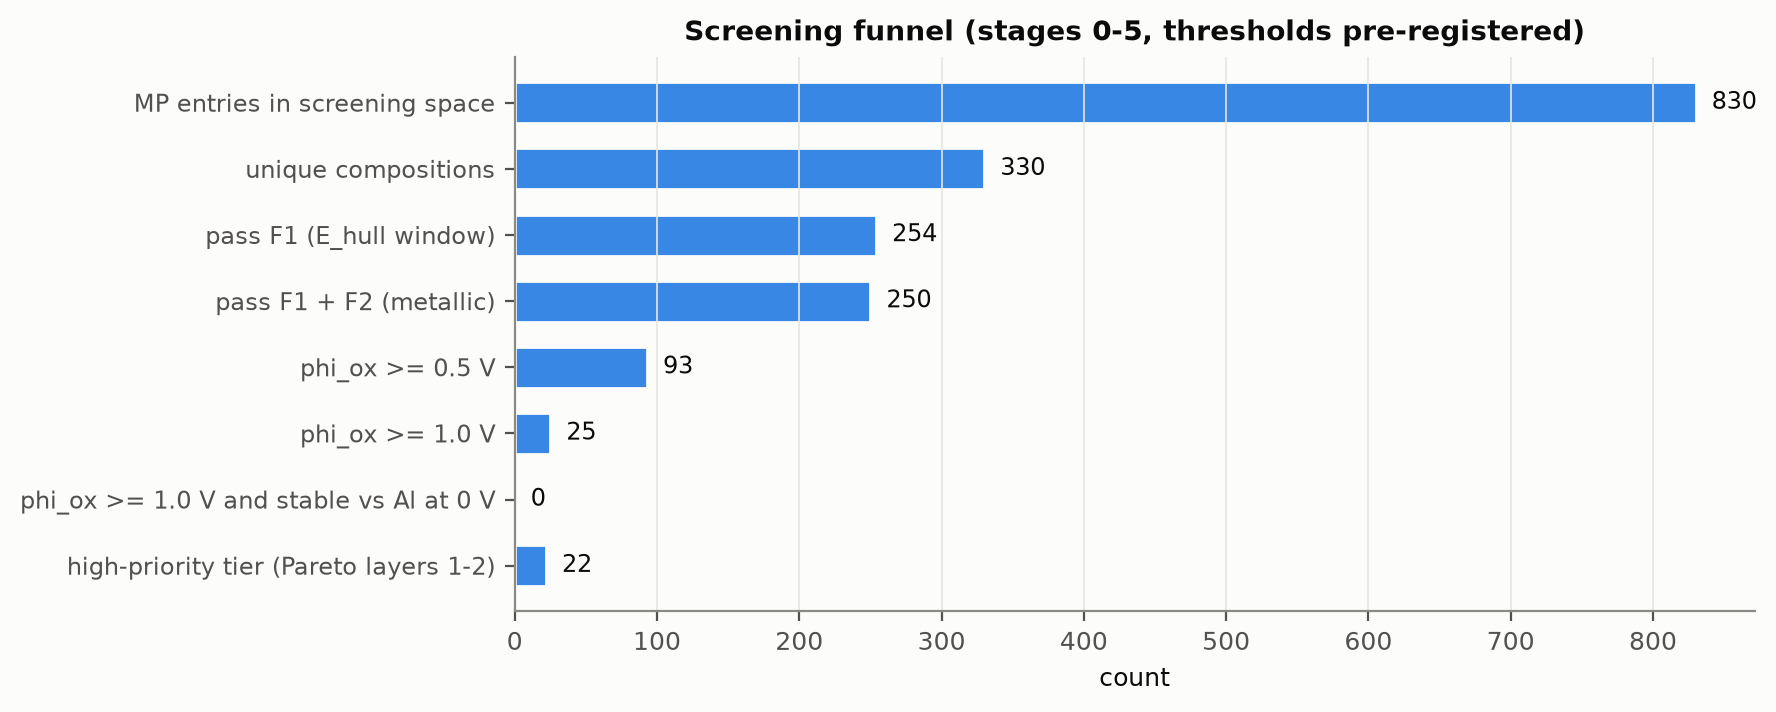

08_stability_windows.png


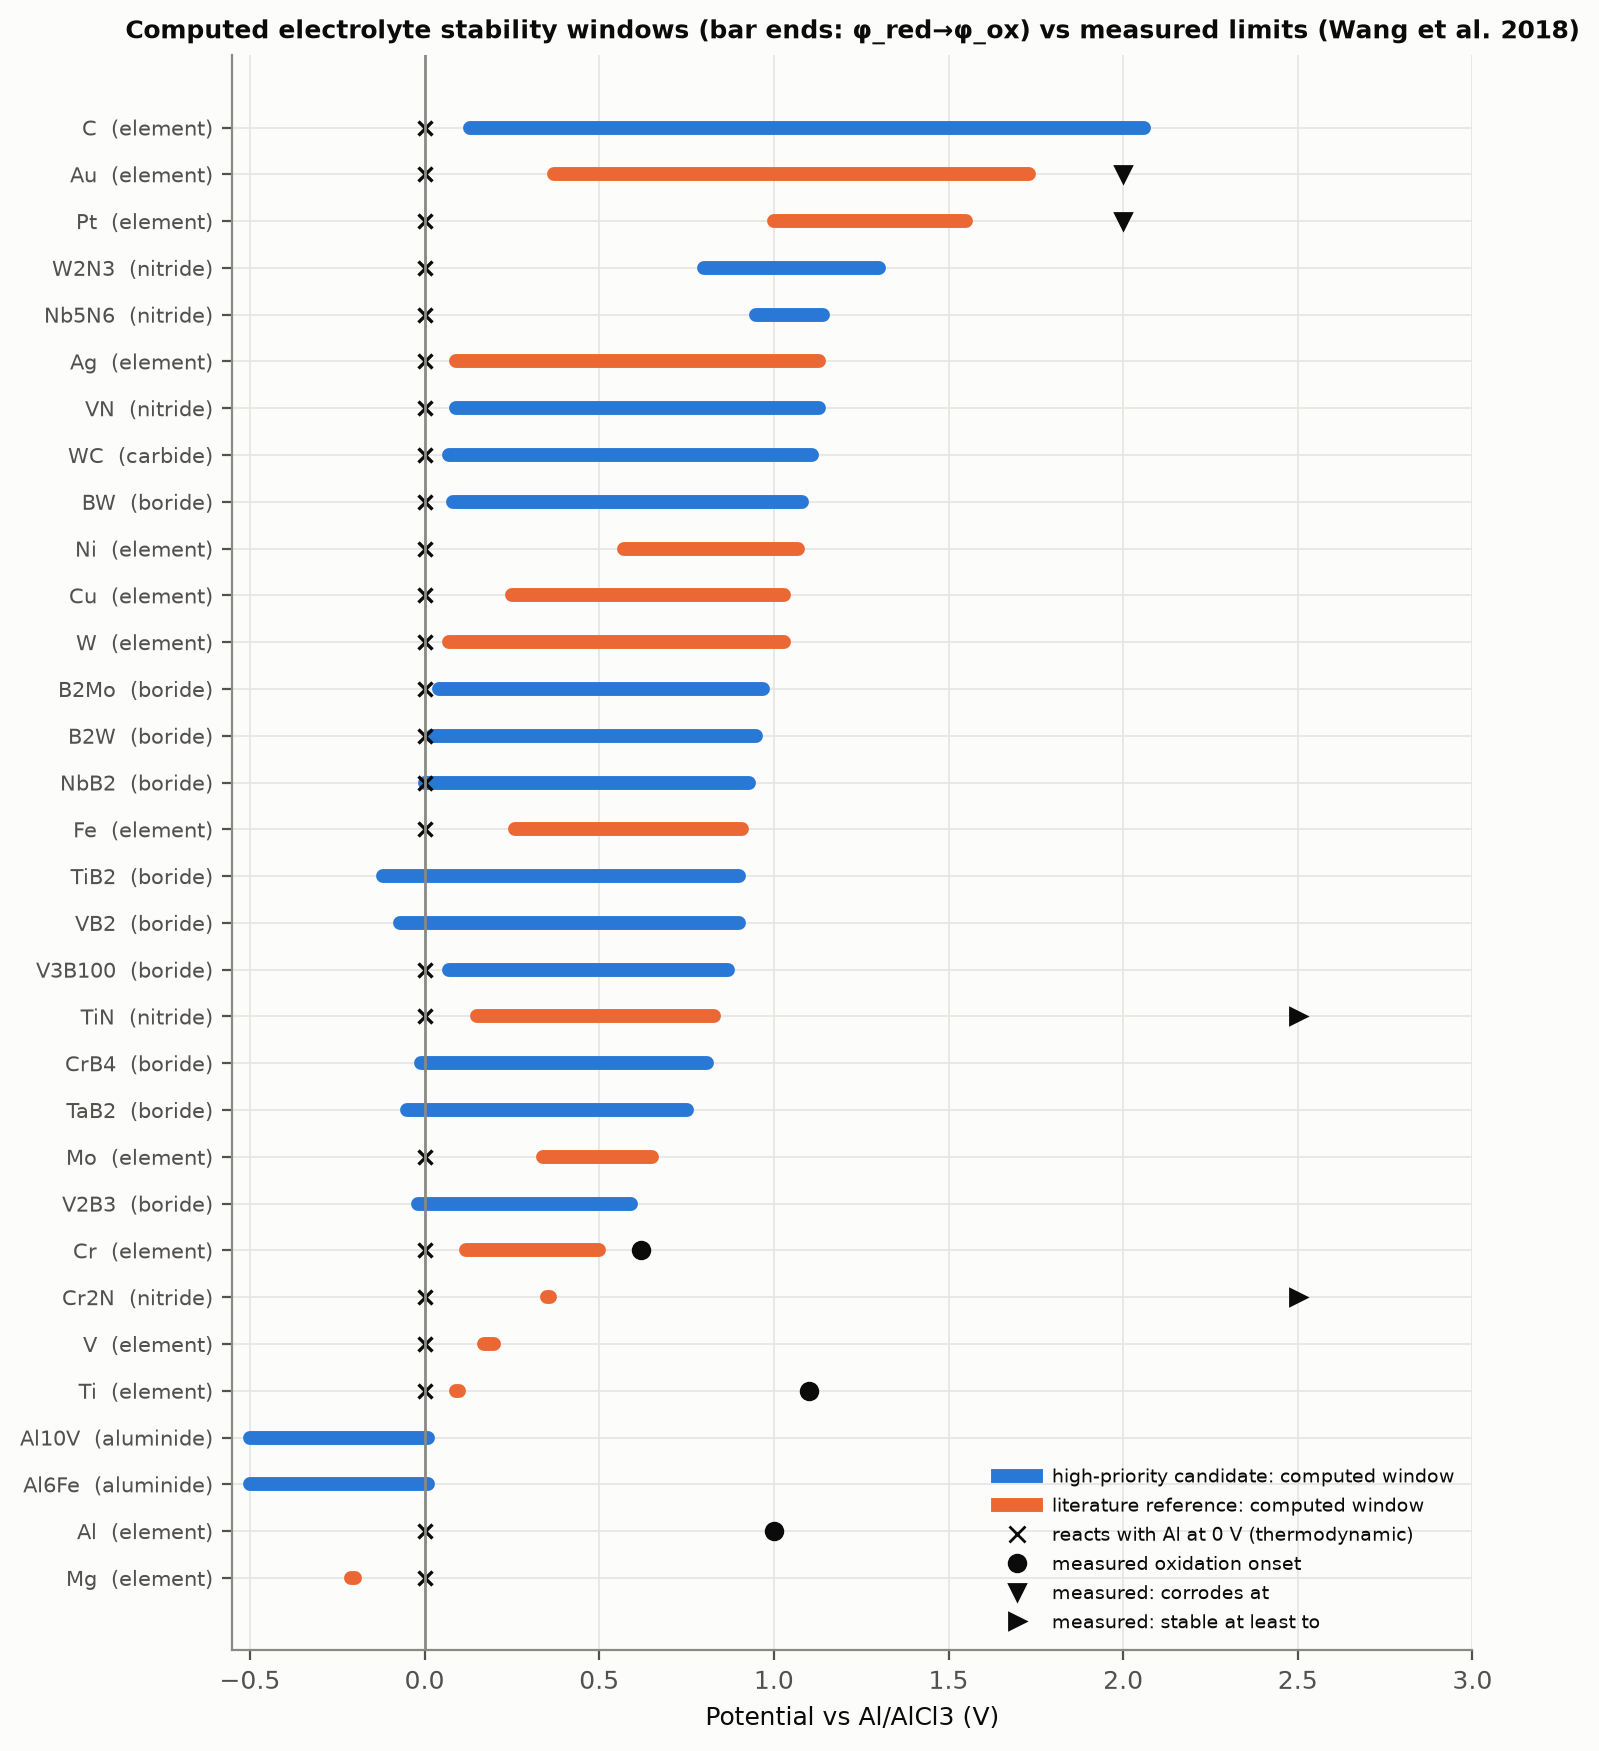

09_pareto.png


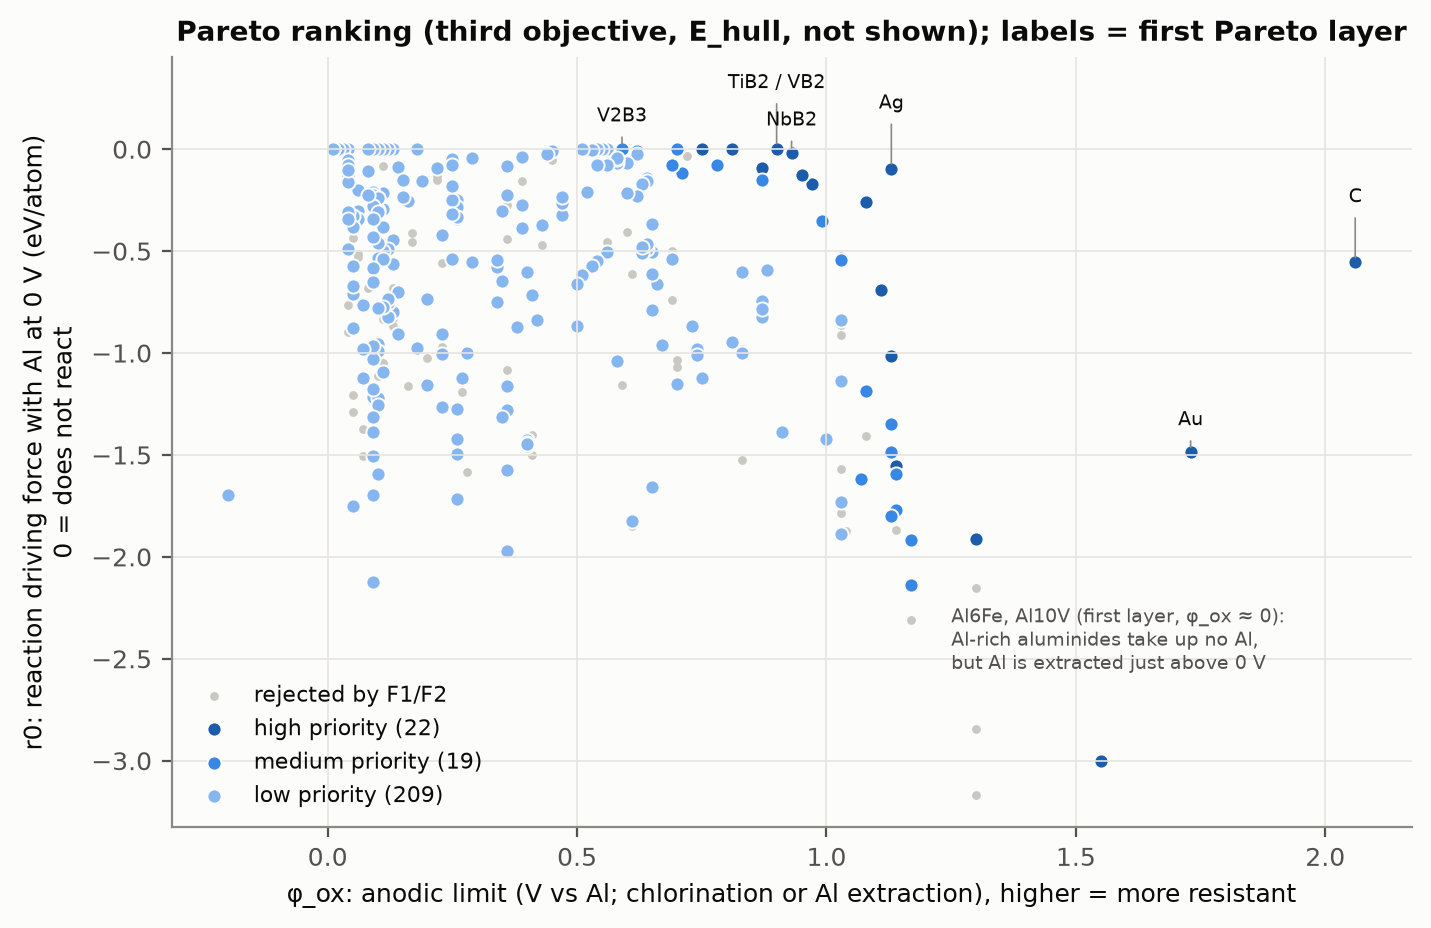

10_validation.png


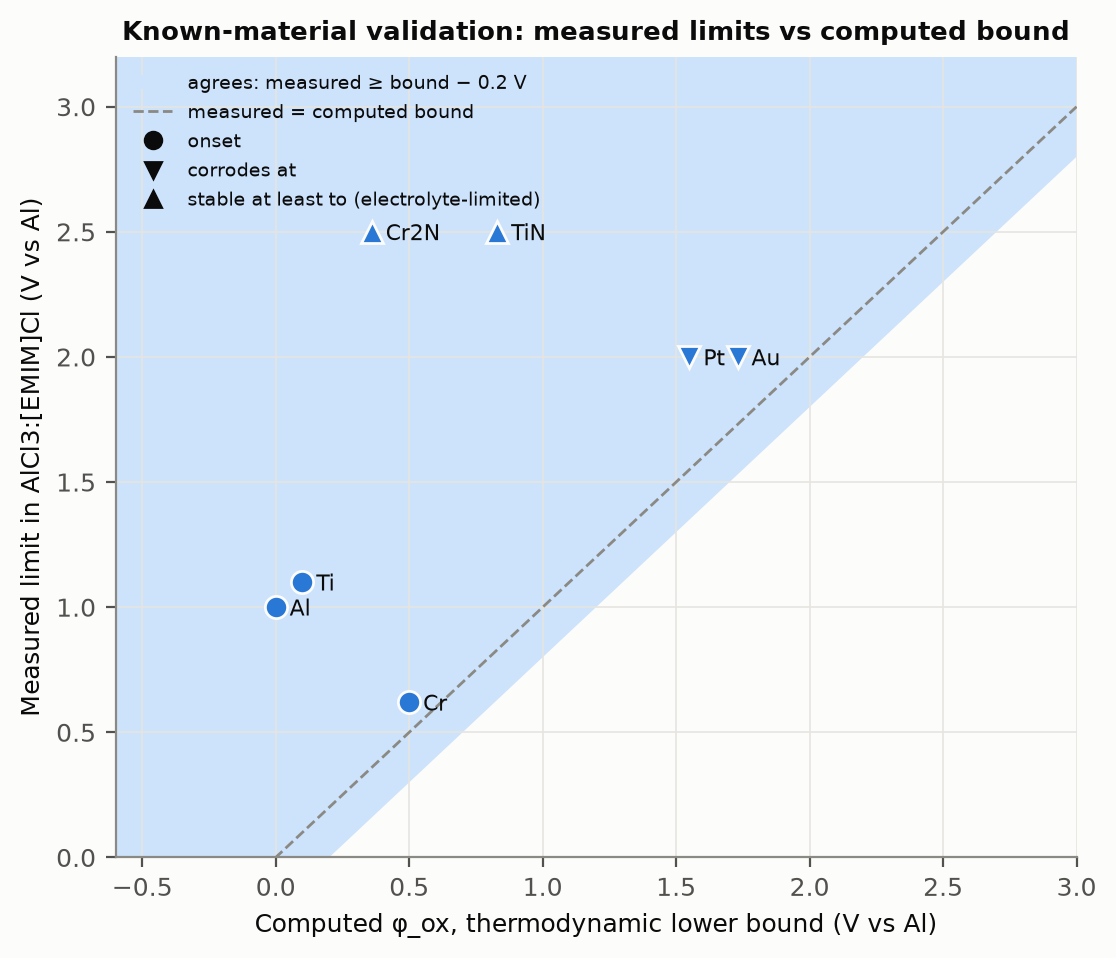

11_applicability_domain.png


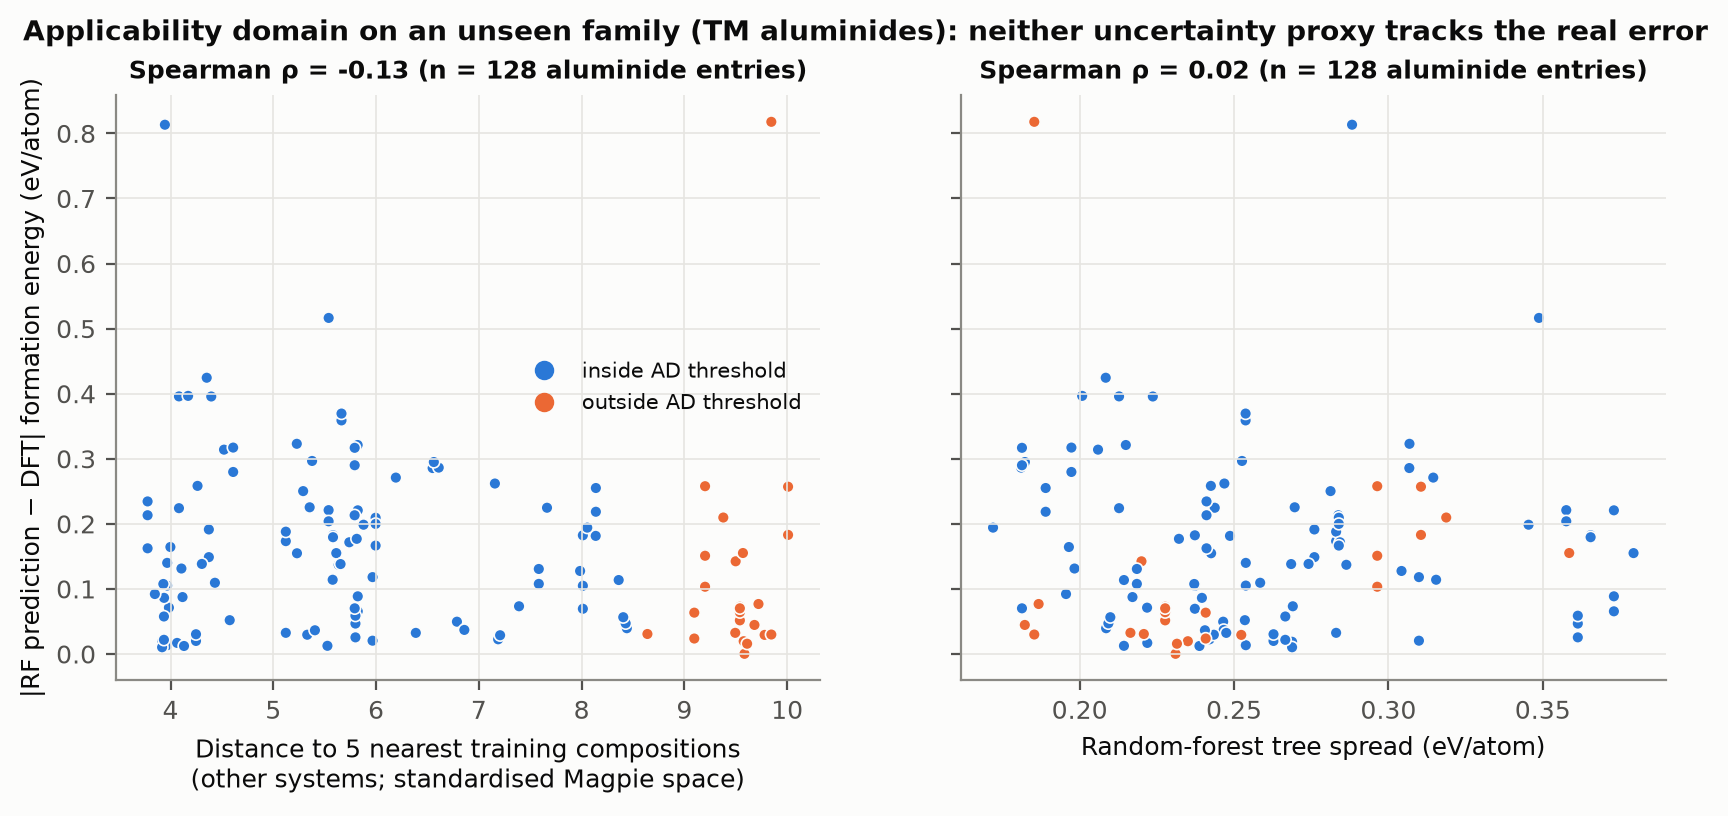

12_sensitivity.png


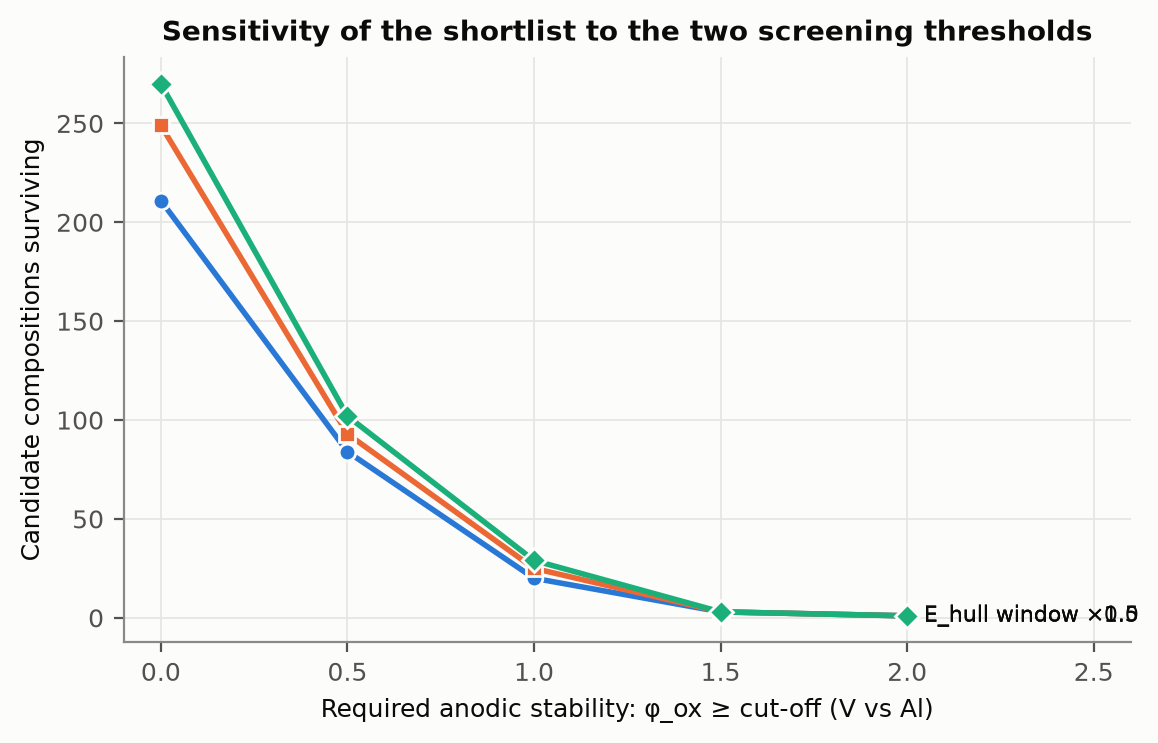

In [11]:
for f in sorted(os.listdir("figures")):
    if f.endswith(".png"):
        print(f); display(Image(filename=os.path.join("figures", f), width=820))

## 8. Limitations and next steps

Bulk thermodynamics only (φ_ox is a lower bound; TiN/Cr₂N/W/Mo work through kinetics); no surface
or nucleation physics yet ("Not available in the current dataset; proposed for Phase 2/DFT");
idealised electrolyte; DFT mixing error (route spread up to 0.42 V; Cr₂N wrongly rejected by F1);
sparse, mostly positive-electrode literature; ML uncertainty proxies do not track error.
See `docs/report.md` for the full list and the November plan.